<a href="https://colab.research.google.com/github/harshpp707/BIOL5340-Cancer-RNASeq-Feature-Selection/blob/main/02_Pilot_SVM.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
from pathlib import Path
from google.colab import drive
import json,time
import numpy as np,pandas as pd,sklearn
import matplotlib.pyplot as plt
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.svm import LinearSVC

In [2]:
drive.mount('/content/drive')
ROOT = Path('/content/drive/MyDrive/BIOL5340_Cancer_RNASeq_Final_Project')
DATA, RESULTS, FIGURES = ROOT/'data', ROOT/'results', ROOT/'results'/'figures'
for p in [DATA, RESULTS, FIGURES]:
    p.mkdir(parents=True, exist_ok=True)
print('Workspace:', ROOT)

Mounted at /content/drive
Workspace: /content/drive/MyDrive/BIOL5340_Cancer_RNASeq_Final_Project


In [3]:

X=pd.read_pickle(DATA/'X_expression.pkl')
y=pd.read_csv(DATA/'y_labels.csv')['cancer_type']
tr=np.load(DATA/'train_indices.npy')
Xtr=X.iloc[tr]; ytr=y.iloc[tr]
SEED=42; FOLDS=3; K_GRID=[25,50,100,500,None]
print('Train:',Xtr.shape,'Scikit-learn:',sklearn.__version__)

Train: (640, 20531) Scikit-learn: 1.6.1


In [4]:
cv=StratifiedKFold(n_splits=FOLDS,shuffle=True,random_state=SEED)
scoring={'macro_f1':'f1_macro','balanced_accuracy':'balanced_accuracy'}
rows=[]
for k in K_GRID:
    steps=[('scale',StandardScaler())]
    if k is not None: steps.append(('select',SelectKBest(score_func=f_classif,k=k)))
    steps.append(('svm',LinearSVC(dual='auto',max_iter=10000,random_state=SEED)))
    pipe=Pipeline(steps)
    t0=time.perf_counter()
    scores=cross_validate(pipe,Xtr,ytr,cv=cv,scoring=scoring,n_jobs=1,error_score='raise')
    rows.append({'method':'ANOVA' if k else 'none','classifier':'LinearSVM',
      'n_features':k if k is not None else Xtr.shape[1],
      'macro_f1_mean':scores['test_macro_f1'].mean(),
      'macro_f1_std':scores['test_macro_f1'].std(),
      'balanced_accuracy_mean':scores['test_balanced_accuracy'].mean(),
      'run_seconds':time.perf_counter()-t0,
      'fold_macro_f1':json.dumps(scores['test_macro_f1'].tolist())})
    print(k if k else 'Full', 'macro-F1:',round(rows[-1]['macro_f1_mean'],4))
pilot=pd.DataFrame(rows)
pilot.to_csv(RESULTS/'pilot_svm_anova.csv',index=False)
display(pilot)

/usr/local/lib/python3.13/dist-packages/sklearn/feature_selection/_univariate_selection.py:111: UserWarning: Features [    5     9    23  3527  4370  4371  4808  4809  4814  4815  4816  4817
  4819  4831  5288  6051  7661  7662  7663  7664  7665  8121  9304  9306
  9309  9314  9316  9318  9320  9323  9350  9452  9744 10121 11130 11230
 11958 12489 12490 12556 12668 12825 13777 13991 14158 14159 14161 14755
 15138 15140 15141 15446 16566 16567 16568 16569 16571 16574 16575 16576
 16578 16579 16604 16634 16637 16677 16697 16698 16699 16700 16701 16702
 16704 16705 16706 16707 16708 16709 16710 16711 16712 16713 16714 16715
 16716 16717 16718 16719 16720 16721 16722 16723 16724 16725 16726 16727
 16728 16729 16730 16731 16732 16733 16734 16735 16736 16737 16738 16739
 16740 16741 16742 16743 16744 16745 16746 16748 16749 16750 16751 16752
 16753 16754 16756 16757 16758 16759 16760 16761 16762 16763 16764 16765
 16766 16767 16768 16769 16770 16771 16772 16774 16775 16776 16777 16778
 16779

25 macro-F1: 0.9987


/usr/local/lib/python3.13/dist-packages/sklearn/feature_selection/_univariate_selection.py:111: UserWarning: Features [    5     9    23  3527  4370  4371  4808  4809  4814  4815  4816  4817
  4819  4831  5288  6051  7661  7662  7663  7664  7665  8121  9304  9306
  9309  9314  9316  9318  9320  9323  9350  9452  9744 10121 11130 11230
 11958 12489 12490 12556 12668 12825 13777 13991 14158 14159 14161 14755
 15138 15140 15141 15446 16566 16567 16568 16569 16571 16574 16575 16576
 16578 16579 16604 16634 16637 16677 16697 16698 16699 16700 16701 16702
 16704 16705 16706 16707 16708 16709 16710 16711 16712 16713 16714 16715
 16716 16717 16718 16719 16720 16721 16722 16723 16724 16725 16726 16727
 16728 16729 16730 16731 16732 16733 16734 16735 16736 16737 16738 16739
 16740 16741 16742 16743 16744 16745 16746 16748 16749 16750 16751 16752
 16753 16754 16756 16757 16758 16759 16760 16761 16762 16763 16764 16765
 16766 16767 16768 16769 16770 16771 16772 16774 16775 16776 16777 16778
 16779

50 macro-F1: 1.0


/usr/local/lib/python3.13/dist-packages/sklearn/feature_selection/_univariate_selection.py:111: UserWarning: Features [    5     9    23  3527  4370  4371  4808  4809  4814  4815  4816  4817
  4819  4831  5288  6051  7661  7662  7663  7664  7665  8121  9304  9306
  9309  9314  9316  9318  9320  9323  9350  9452  9744 10121 11130 11230
 11958 12489 12490 12556 12668 12825 13777 13991 14158 14159 14161 14755
 15138 15140 15141 15446 16566 16567 16568 16569 16571 16574 16575 16576
 16578 16579 16604 16634 16637 16677 16697 16698 16699 16700 16701 16702
 16704 16705 16706 16707 16708 16709 16710 16711 16712 16713 16714 16715
 16716 16717 16718 16719 16720 16721 16722 16723 16724 16725 16726 16727
 16728 16729 16730 16731 16732 16733 16734 16735 16736 16737 16738 16739
 16740 16741 16742 16743 16744 16745 16746 16748 16749 16750 16751 16752
 16753 16754 16756 16757 16758 16759 16760 16761 16762 16763 16764 16765
 16766 16767 16768 16769 16770 16771 16772 16774 16775 16776 16777 16778
 16779

100 macro-F1: 1.0


/usr/local/lib/python3.13/dist-packages/sklearn/feature_selection/_univariate_selection.py:111: UserWarning: Features [    5     9    23  3527  4370  4371  4808  4809  4814  4815  4816  4817
  4819  4831  5288  6051  7661  7662  7663  7664  7665  8121  9304  9306
  9309  9314  9316  9318  9320  9323  9350  9452  9744 10121 11130 11230
 11958 12489 12490 12556 12668 12825 13777 13991 14158 14159 14161 14755
 15138 15140 15141 15446 16566 16567 16568 16569 16571 16574 16575 16576
 16578 16579 16604 16634 16637 16677 16697 16698 16699 16700 16701 16702
 16704 16705 16706 16707 16708 16709 16710 16711 16712 16713 16714 16715
 16716 16717 16718 16719 16720 16721 16722 16723 16724 16725 16726 16727
 16728 16729 16730 16731 16732 16733 16734 16735 16736 16737 16738 16739
 16740 16741 16742 16743 16744 16745 16746 16748 16749 16750 16751 16752
 16753 16754 16756 16757 16758 16759 16760 16761 16762 16763 16764 16765
 16766 16767 16768 16769 16770 16771 16772 16774 16775 16776 16777 16778
 16779

500 macro-F1: 1.0
Full macro-F1: 0.9975


,method,classifier,n_features,macro_f1_mean,macro_f1_std,balanced_accuracy_mean,run_seconds,fold_macro_f1
0,ANOVA,LinearSVM,25,0.998697,0.001843,0.998246,2.552988,"[0.9960910973084885, 1.0, 1.0]"
1,ANOVA,LinearSVM,50,1.000000,0.000000,1.000000,2.013686,"[1.0, 1.0, 1.0]"
2,ANOVA,LinearSVM,100,1.000000,0.000000,1.000000,2.068393,"[1.0, 1.0, 1.0]"
3,ANOVA,LinearSVM,500,1.000000,0.000000,1.000000,2.519695,"[1.0, 1.0, 1.0]"
4,none,LinearSVM,20531,0.997485,0.003557,0.998246,17.571523,"[0.9924552845528456, 1.0, 1.0]"


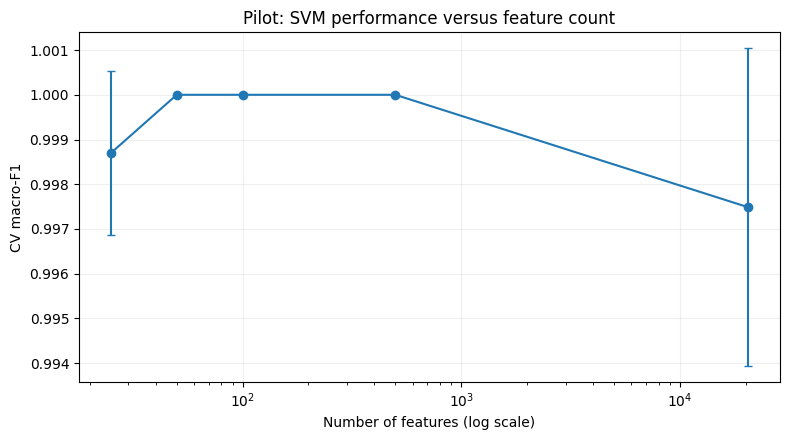

In [5]:
fig,ax=plt.subplots(figsize=(8,4.5))
s=pilot.sort_values('n_features')
ax.errorbar(s['n_features'],s['macro_f1_mean'],yerr=s['macro_f1_std'],marker='o',capsize=3)
ax.set_xscale('log');ax.set_xlabel('Number of features (log scale)')
ax.set_ylabel('CV macro-F1');ax.set_title('Pilot: SVM performance versus feature count')
ax.grid(alpha=.2);fig.tight_layout();fig.savefig(FIGURES/'pilot_f1_vs_feature_count.png',dpi=180)
plt.show()